In [ ]:
!pip install tensorflow opencv-python-headless pandas scikit-learn matplotlib seaborn -q

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import urllib.request
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [ ]:
# =========== Load dataset ===========
from google.colab import drive
drive.mount('/content/drive')

images_folder = "/content/drive/MyDrive/Colab Notebooks/Dataset/stored-faces"
csv_file = "/content/drive/MyDrive/Colab Notebooks/Dataset/data.csv"

df = pd.read_csv(csv_file)
df["ID"] = df["ID"].astype(str)

print(df.head())
print(os.listdir(images_folder))

Mounted at /content/drive
      Role    ID          Name  Gender Faculty                  Course
0    Staff  E001  Henry Cavill    Male    FAFB                     NaN
1  Student  S001   Lisa Kudrow  Female    FAFB   Diploma in Accounting
2  Student  S002    Alia Bhatt  Female    FOAS  Bachelor in Bioscience
3    Staff  E002    Tom Cruise    Male    FOCS                     NaN
4    Staff  E003     Zac Efron    Male    FAFB                     NaN
['E001', 'S001', 'S002', 'E002', 'E003', 'S003', 'S004', 'E004', 'E005', 'S005', 'S006', 'S007', 'S008', 'S009', 'S010', 'S011', 'S012', 'E006', 'S013', 'S014', 'E007', 'S015', 'S016', 'E008', 'E009', 'S017', 'S018', 'S019', 'E010', 'S020', 'S022', 'S023', 'S024', 'S025', 'S021']


In [ ]:
IMG_SIZE = 100

YUNET_MODEL_URL = "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx"
YUNET_MODEL_PATH = "face_detection_yunet_2023mar.onnx"

YUNET_SCORE_THRESHOLD = 0.7   # min confidence to keep a detection
YUNET_NMS_THRESHOLD = 0.3     # non-max suppression IoU threshold
YUNET_TOP_K = 5000            # max detections kept before NMS
YUNET_MIN_FACE_SIZE = 60      # matches the old Haar minSize=(60, 60)

urllib.request.urlretrieve(YUNET_MODEL_URL,YUNET_MODEL_PATH)

face_detector = cv2.FaceDetectorYN.create(
    YUNET_MODEL_PATH, "", (320, 320),
    YUNET_SCORE_THRESHOLD, YUNET_NMS_THRESHOLD, YUNET_TOP_K,
)

def detect_faces_yunet(image):
    """
    Runs YuNet on a BGR image and returns a list of (x, y, w, h) int boxes,
    the same shape CascadeClassifier.detectMultiScale used to return -- so
    downstream code (largest-face selection, cropping) is unchanged.
    """
    h, w = image.shape[:2]
    face_detector.setInputSize((w, h))
    _, faces = face_detector.detect(image)
    boxes = []
    if faces is not None:
        for f in faces:
            x, y, fw, fh = f[:4]
            x, y, fw, fh = int(round(x)), int(round(y)), int(round(fw)), int(round(fh))
            if fw >= YUNET_MIN_FACE_SIZE and fh >= YUNET_MIN_FACE_SIZE:
                boxes.append((max(x, 0), max(y, 0), fw, fh))
    return boxes

def detect_and_crop_face(image):
    """
    Returns the largest detected face crop (grayscale, IMG_SIZE x IMG_SIZE), or None.
    """
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    faces = detect_faces_yunet(image)
    if len(faces) == 0:
        return None
    x, y, w, h = max(faces, key=lambda f: f[2] * f[3])
    face = gray[y:y+h, x:x+w]
    face = cv2.resize(face, (IMG_SIZE, IMG_SIZE))
    return face

X, y = [], []
skipped = 0

for person_id in sorted(os.listdir(images_folder)):
    person_dir = os.path.join(images_folder, person_id)
    if not os.path.isdir(person_dir):
        continue
    for filename in os.listdir(person_dir):
        if not filename.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):
            continue
        filepath = os.path.join(person_dir, filename)
        image = cv2.imread(filepath)

        if image is None:
            print(f"[Unreadable] {filepath}")
            skipped += 1
            continue

        face = detect_and_crop_face(image)

        if face is None:
            print(f"[No face detected] {filepath}")
            skipped += 1
            continue
        X.append(face)
        y.append(person_id)

X = np.array(X, dtype=np.float32) / 255.0
X = np.expand_dims(X, axis=-1)  # add channel dim -> (N, IMG_SIZE, IMG_SIZE, 1)
y = np.array(y)

print("Total usable images:", len(X))
print("Skipped (no face found / unreadable):", skipped)
print("Number of people (classes):", len(np.unique(y)))
print("Images per person:")
print(pd.Series(y).value_counts())

[No face detected] /content/drive/MyDrive/Colab Notebooks/Dataset/stored-faces/E001/Henry_Cavill_018.jpg
[No face detected] /content/drive/MyDrive/Colab Notebooks/Dataset/stored-faces/E001/Henry_Cavill_045.jpg
[No face detected] /content/drive/MyDrive/Colab Notebooks/Dataset/stored-faces/E001/Henry_Cavill_033.jpg
[No face detected] /content/drive/MyDrive/Colab Notebooks/Dataset/stored-faces/E001/Henry_Cavill_068.jpg
[No face detected] /content/drive/MyDrive/Colab Notebooks/Dataset/stored-faces/E001/Henry_Cavill_027.jpg
[No face detected] /content/drive/MyDrive/Colab Notebooks/Dataset/stored-faces/E001/Henry_Cavill_029.jpg
[No face detected] /content/drive/MyDrive/Colab Notebooks/Dataset/stored-faces/E001/Henry_Cavill_036.jpg
[No face detected] /content/drive/MyDrive/Colab Notebooks/Dataset/stored-faces/E001/Henry_Cavill_090.jpg
[No face detected] /content/drive/MyDrive/Colab Notebooks/Dataset/stored-faces/E001/Henry_Cavill_008.jpg
[No face detected] /content/drive/MyDrive/Colab Noteboo

In [ ]:
# =========== Face Mask Detector (pretrained) ===========
# Pretrained MobileNetV2-based mask / no-mask classifier
# (Chandrika Deb, "Face-Mask-Detection", MIT License)
import urllib.request
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import AveragePooling2D, Dropout, Flatten, Dense, Input
from tensorflow.keras.models import Model

MASK_MODEL_PATH = "mask_detector.h5"
MASK_MODEL_URL = "https://raw.githubusercontent.com/chandrikadeb7/Face-Mask-Detection/master/mask_detector.model"
MASK_IMG_SIZE = 224  # input size expected by this pretrained model

if not os.path.exists(MASK_MODEL_PATH):
    urllib.request.urlretrieve(MASK_MODEL_URL, MASK_MODEL_PATH)

_base = MobileNetV2(weights=None, include_top=False, input_tensor=Input(shape=(MASK_IMG_SIZE, MASK_IMG_SIZE, 3)))
_head = _base.output
_head = AveragePooling2D(pool_size=(7, 7))(_head)
_head = Flatten(name="flatten")(_head)
_head = Dense(128, activation="relu")(_head)
_head = Dropout(0.5)(_head)
_head = Dense(2, activation="softmax")(_head)
mask_net = Model(inputs=_base.input, outputs=_head)
mask_net.load_weights(MASK_MODEL_PATH)

def is_wearing_mask(face_bgr):
    """
    Runs the pretrained mask detector on a BGR face crop.
    face_bgr should be the raw color crop straight from the original frame
    (before any grayscale conversion / resizing done for the recognition model).
    Returns True if a mask is detected, False otherwise.
    """
    face_rgb = cv2.cvtColor(face_bgr, cv2.COLOR_BGR2RGB)
    face_resized = cv2.resize(face_rgb, (MASK_IMG_SIZE, MASK_IMG_SIZE))
    face_array = tf.keras.preprocessing.image.img_to_array(face_resized)
    face_array = tf.keras.applications.mobilenet_v2.preprocess_input(face_array)
    face_array = np.expand_dims(face_array, axis=0)

    (mask_prob, without_mask_prob) = mask_net.predict(face_array, verbose=0)[0]
    return mask_prob > without_mask_prob


In [ ]:
if len(X) == 0:
    raise Exception("No faces found. Check images_folder and that each person has enrolled images.")

if pd.Series(y).value_counts().min() < 5:
    print("WARNING: some people have very few images (<5). Accuracy will suffer — "
          "aim for at least 15-20 images per person, taken with varied angle/lighting/expression.")

In [ ]:
# =========== Encode labels and split train, validation, and test data ===========
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
num_classes = len(label_encoder.classes_)
y_categorical = to_categorical(y_encoded, num_classes=num_classes)

RANDOM_SEED = 42  # fixed seed for both split levels

X_trainval, X_test, y_trainval, y_test, y_trainval_encoded, y_test_encoded = train_test_split(
    X, y_categorical, y_encoded,
    test_size=0.15,
    random_state=RANDOM_SEED,
    stratify=y_encoded
)

val_fraction_of_trainval = 0.15 / (1 - 0.15)

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval,
    test_size=val_fraction_of_trainval,
    random_state=RANDOM_SEED,
    stratify=y_trainval_encoded
)

print("Train samples:     ", X_train.shape[0])
print("Validation samples:", X_val.shape[0])
print("Test samples:      ", X_test.shape[0])
print("Classes:", list(label_encoder.classes_))


Train samples:      1867
Validation samples: 401
Test samples:       401
Classes: [np.str_('E001'), np.str_('E002'), np.str_('E003'), np.str_('E004'), np.str_('E005'), np.str_('E006'), np.str_('E007'), np.str_('E008'), np.str_('E009'), np.str_('E010'), np.str_('S001'), np.str_('S002'), np.str_('S003'), np.str_('S004'), np.str_('S005'), np.str_('S006'), np.str_('S007'), np.str_('S008'), np.str_('S009'), np.str_('S010'), np.str_('S011'), np.str_('S012'), np.str_('S013'), np.str_('S014'), np.str_('S015'), np.str_('S016'), np.str_('S017'), np.str_('S018'), np.str_('S019'), np.str_('S020'), np.str_('S021'), np.str_('S022'), np.str_('S023'), np.str_('S024'), np.str_('S025')]


In [ ]:
# =========== Build CNN ===========
def build_cnn(input_shape, num_classes):
    model = models.Sequential([
        layers.Input(shape=input_shape),

        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.GlobalAveragePooling2D(),
        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax'),
    ])
    return model

model = build_cnn((IMG_SIZE, IMG_SIZE, 1), num_classes)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 100, 100, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 100, 100, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 50, 50, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 50, 50, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 25, 25, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 25, 25, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 35)             │         8,995 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 465,571 (1.78 MB)

 Trainable params: 464,099 (1.77 MB)

 Non-trainable params: 1,472 (5.75 KB)

In [ ]:
# =========== Data augmentation ===========
train_datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode="nearest"
)

# =========== Data training ===========
EPOCHS = 80

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "best_cnn.keras",
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    train_datagen.flow(
        X_train,
        y_train,
        batch_size=32,
        shuffle=True
    ),
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/80
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 849ms/step - accuracy: 0.5719 - loss: 1.4567
Epoch 1: val_accuracy improved from None to 0.29676, saving model to best_cnn.keras

Epoch 1: finished saving model to best_cnn.keras
59/59 ━━━━━━━━━━━━━━━━━━━━ 53s 883ms/step - accuracy: 0.5661 - loss: 1.4499 - val_accuracy: 0.2968 - val_loss: 2.5779 - learning_rate: 5.0000e-04
Epoch 2/80
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 720ms/step - accuracy: 0.6073 - loss: 1.2786
Epoch 2: val_accuracy did not improve from 0.29676
59/59 ━━━━━━━━━━━━━━━━━━━━ 44s 753ms/step - accuracy: 0.5919 - loss: 1.3101 - val_accuracy: 0.2643 - val_loss: 2.9406 - learning_rate: 5.0000e-04
Epoch 3/80
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 773ms/step - accuracy: 0.5997 - loss: 1.3012
Epoch 3: val_accuracy improved from 0.29676 to 0.46633, saving model to best_cnn.keras

Epoch 3: finished saving model to best_cnn.keras
59/59 ━━━━━━━━━━━━━━━━━━━━ 48s 806ms/step - accuracy: 0.6192 - loss: 1.2460 - val_accuracy: 0.4663 - val_loss: 1.7929 - learning

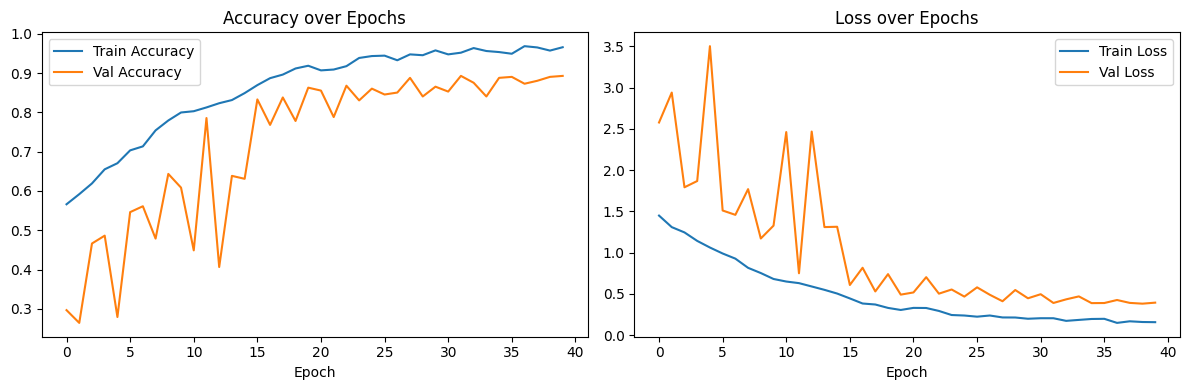

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history.history['accuracy'], label='Train Accuracy')
ax[0].plot(history.history['val_accuracy'], label='Val Accuracy')
ax[0].set_title('Accuracy over Epochs')
ax[0].set_xlabel('Epoch')
ax[0].legend()

ax[1].plot(history.history['loss'], label='Train Loss')
ax[1].plot(history.history['val_loss'], label='Val Loss')
ax[1].set_title('Loss over Epochs')
ax[1].set_xlabel('Epoch')
ax[1].legend()

plt.tight_layout()
plt.show()


In [ ]:
# =========== Evaluate training, validation, and test accuracy ===========
train_loss, train_acc = model.evaluate(X_train, y_train, verbose=0)
val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)

print(f"Training Accuracy:   {train_acc*100:.2f}%")
print(f"Validation Accuracy: {val_acc*100:.2f}%")
print(f"Test Accuracy:       {test_acc*100:.2f}%")


Training Accuracy:   98.98%
Validation Accuracy: 89.28%
Test Accuracy:       87.03%


13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 151ms/step
              precision    recall  f1-score   support

        E001       0.71      0.86      0.77        14
        E002       0.67      1.00      0.80         8
        E003       0.83      0.83      0.83        12
        E004       1.00      1.00      1.00         9
        E005       1.00      0.80      0.89        15
        E006       1.00      1.00      1.00        11
        E007       0.91      0.91      0.91        11
        E008       0.82      0.75      0.78        12
        E009       0.82      0.82      0.82        17
        E010       0.83      1.00      0.91        10
        S001       1.00      0.80      0.89        10
        S002       0.92      1.00      0.96        11
        S003       0.94      0.94      0.94        16
        S004       1.00      0.67      0.80         6
        S005       0.72      0.93      0.81        14
        S006       0.63      0.86      0.73        14
        S007       0.89      1.00      0

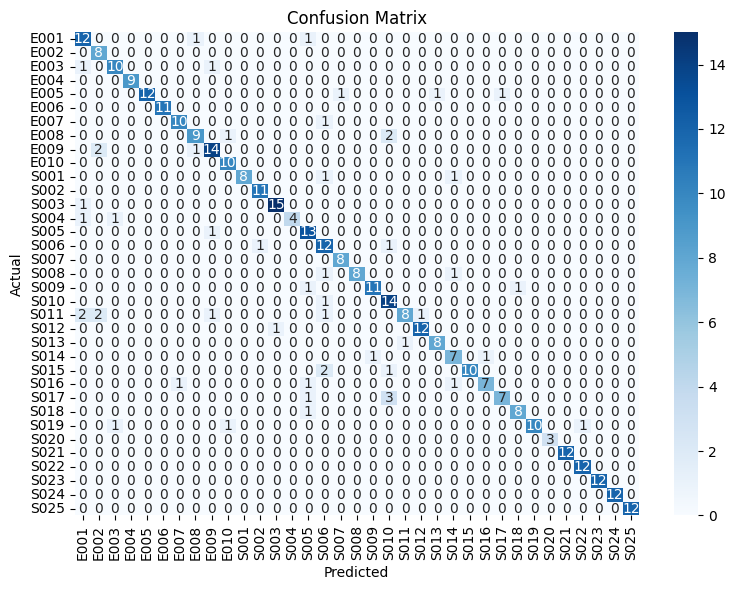

In [ ]:
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.argmax(y_test, axis=1)

print(classification_report(
    y_true, y_pred,
    target_names=label_encoder.classes_,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

Selected CONFIDENCE_THRESHOLD = 0.389 (maximizes F1 on the validation set)
  At this threshold -> precision: 0.924, recall: 0.980, F1: 0.951
  ROC AUC (confidence vs. correctness): 0.921


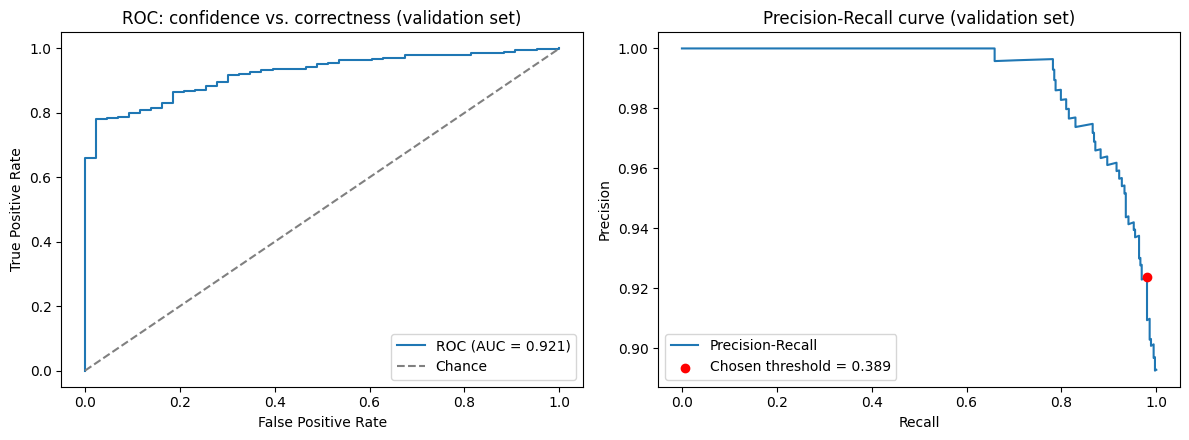

In [ ]:
# =========== Confidence Threshold Selection ===========
from sklearn.metrics import roc_curve, auc, precision_recall_curve

val_probs = model.predict(X_val, verbose=0)
val_pred = np.argmax(val_probs, axis=1)
val_true = np.argmax(y_val, axis=1)
val_conf = np.max(val_probs, axis=1)
val_correct = (val_pred == val_true).astype(int)

fpr, tpr, _ = roc_curve(val_correct, val_conf)
roc_auc = auc(fpr, tpr)

precision, recall, pr_thresholds = precision_recall_curve(val_correct, val_conf)
f1_scores = np.divide(
    2 * precision * recall, precision + recall,
    out=np.zeros_like(precision), where=(precision + recall) > 0
)
best_idx = np.argmax(f1_scores[:-1]) if len(f1_scores) > 1 else 0
CONFIDENCE_THRESHOLD = float(pr_thresholds[best_idx]) if len(pr_thresholds) > 0 else 0.5

print(f"Selected CONFIDENCE_THRESHOLD = {CONFIDENCE_THRESHOLD:.3f} "
      f"(maximizes F1 on the validation set)")
print(f"  At this threshold -> precision: {precision[best_idx]:.3f}, "
      f"recall: {recall[best_idx]:.3f}, F1: {f1_scores[best_idx]:.3f}")
print(f"  ROC AUC (confidence vs. correctness): {roc_auc:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].plot(fpr, tpr, label=f"ROC (AUC = {roc_auc:.3f})")
ax[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
ax[0].set_xlabel("False Positive Rate")
ax[0].set_ylabel("True Positive Rate")
ax[0].set_title("ROC: confidence vs. correctness (validation set)")
ax[0].legend(loc="lower right")

ax[1].plot(recall, precision, label="Precision-Recall")
ax[1].scatter(recall[best_idx], precision[best_idx], color="red", zorder=5,
              label=f"Chosen threshold = {CONFIDENCE_THRESHOLD:.3f}")
ax[1].set_xlabel("Recall")
ax[1].set_ylabel("Precision")
ax[1].set_title("Precision-Recall curve (validation set)")
ax[1].legend(loc="lower left")

plt.tight_layout()
plt.show()


In [ ]:
# =========== Evaluates the chosen threshold on the test set ===========
test_conf = np.max(y_pred_probs, axis=1)
test_correct = (y_pred == y_true)
accepted = test_conf >= CONFIDENCE_THRESHOLD
n_accepted = accepted.sum()

print(f"Test predictions accepted (confidence >= {CONFIDENCE_THRESHOLD:.3f}): "
      f"{n_accepted}/{len(y_true)} ({100*n_accepted/len(y_true):.1f}%)")
if n_accepted > 0:
    print(f"Accuracy among accepted predictions:  {100*test_correct[accepted].mean():.2f}%")
n_rejected_but_correct = np.sum((~accepted) & test_correct)
print(f"Correct predictions rejected by the threshold: {n_rejected_but_correct} "
      f"(would have been right, but confidence was below the cutoff)")


Test predictions accepted (confidence >= 0.389): 378/401 (94.3%)
Accuracy among accepted predictions:  90.48%
Correct predictions rejected by the threshold: 7 (would have been right, but confidence was below the cutoff)


In [ ]:
# =========== Save models ===========
save_dir = "/content/drive/MyDrive/Colab Notebooks/Dataset/models1/"
os.makedirs(save_dir, exist_ok=True)

model.save(save_dir + "face_cnn_model.keras")
np.save(save_dir + "label_classes.npy", label_encoder.classes_)

np.save(save_dir + "confidence_threshold.npy", CONFIDENCE_THRESHOLD)
print("Saved all files.")